# ECG200 Algorithm 4 Barycenter Visualizations

This notebook visualizes the Algorithm 4 W1 subspace enumeration results for the ECG200 heartbeat dataset (k=10 heartbeats per class, 96 points per heartbeat, t=2, MOSEK solver).

It produces three visualizations:
1. **Wasserstein barycenter vs Euclidean mean** — compares the barycenter support points against a pointwise Euclidean mean of the input heartbeats.
2. **Peak timing vs peak height** — scatter plot of each input heartbeat's peak location and peak amplitude.
3. **2D density heatmap** — 2D histogram of the barycenter support points, colored by probability mass.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(__file__).resolve().parent if '__file__' in dir() else Path.cwd()
print(f"Results directory: {RESULTS_DIR}")

Results directory: /Users/vincentcollinyennoto/Downloads/fyp-barycenter-implementation/src/closing_gap_reproduction/results/ecg200_k10_n96_t2


## Load input waveforms and barycenter results

We load the saved Algorithm 4 results for both classes: normal ('1') and abnormal ('-1'). Each class has 10 input heartbeats with 96 points each.

In [3]:
def load_class_data(class_name):
    """Load input waveforms and barycenter result for a given class."""
    stem = f"ecg200_{class_name}_k10_n96_algo4_t2_mosek"
    
    # Load inputs
    inputs_npz = np.load(RESULTS_DIR / f"{stem}_inputs.npz")
    waveforms = inputs_npz["waveforms"]          # (10, 96) raw ECG amplitudes
    X = inputs_npz["X"]                           # (10, 96, 2) [time, amplitude] per measure
    w = inputs_npz["w"]                           # (10, 96) marginal weights
    retained_indices = inputs_npz["retained_time_indices"]
    
    # Load barycenter result
    result_npz = np.load(RESULTS_DIR / f"{stem}.npz")
    S = result_npz["S"]                           # (N, 2) barycenter support points
    z = result_npz["z"]                           # (N,) barycenter weights
    objective = float(result_npz["objective"])
    
    # Normalized time axis (0 to 1)
    times = np.linspace(0.0, 1.0, 96)
    
    return {
        "class_name": class_name,
        "waveforms": waveforms,
        "times": times,
        "S": S,
        "z": z,
        "objective": objective,
        "active_mask": z > 1e-12,
    }

In [4]:
normal = load_class_data("normal")
abnormal = load_class_data("abnormal")

for cls in (normal, abnormal):
    print(f"{cls['class_name']}: {cls['waveforms'].shape[0]} heartbeats, "
          f"{cls['S'].shape[0]} support points, {cls['active_mask'].sum()} active atoms, "
          f"objective={cls['objective']:.6g}")

normal: 10 heartbeats, 960 support points, 306 active atoms, objective=0.1684
abnormal: 10 heartbeats, 960 support points, 285 active atoms, objective=0.212777


## Visualization 1: Wasserstein barycenter vs Euclidean mean

For each class, we plot:
- All input heartbeats (faint lines)
- The Euclidean mean (pointwise average across heartbeats, thick line)
- The Wasserstein barycenter support points (scatter, colored by probability mass; fixed size, with transparency to reveal stacked points)

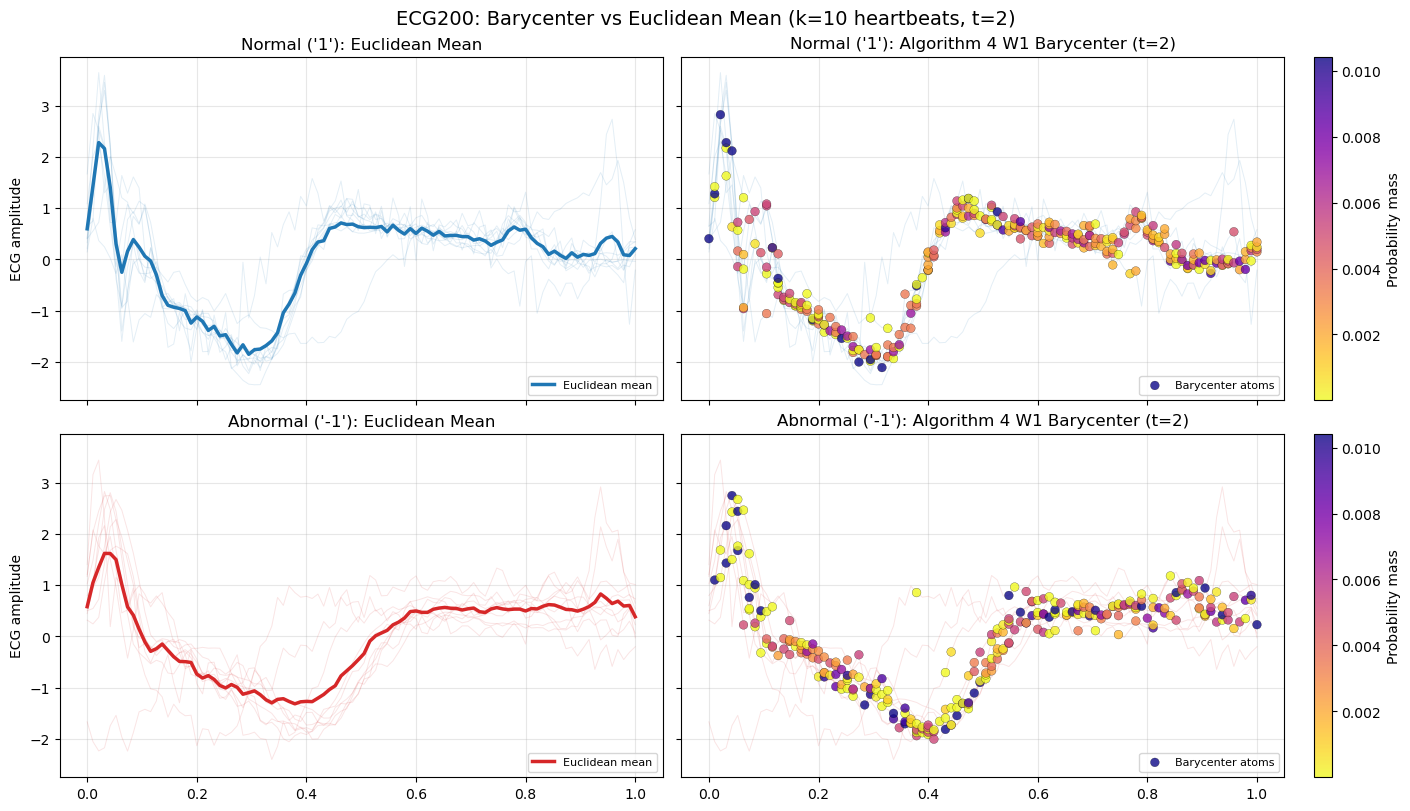

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True,
                           constrained_layout=True)

class_info = [
    (normal, "#1f77b4", "Normal ('1')"),
    (abnormal, "#d62728", "Abnormal ('-1')"),
]

for row, (cls, color, title) in enumerate(class_info):
    waveforms = cls["waveforms"]
    times = cls["times"]
    S = cls["S"]
    z = cls["z"]
    active = cls["active_mask"]
    
    # Euclidean mean (pointwise average)
    euclidean_mean = waveforms.mean(axis=0)
    
    # Left panel: Euclidean mean
    ax_e = axes[row, 0]
    ax_e.plot(times, waveforms.T, color=color, alpha=0.12, linewidth=0.7)
    ax_e.plot(times, euclidean_mean, color=color, linewidth=2.5, label="Euclidean mean")
    ax_e.set_ylabel("ECG amplitude")
    ax_e.set_title(f"{title}: Euclidean Mean")
    ax_e.legend(fontsize=8, loc="lower right")
    ax_e.grid(True, alpha=0.3)
    
    # Right panel: Wasserstein barycenter
    ax_w = axes[row, 1]
    ax_w.plot(times, waveforms.T, color=color, alpha=0.12, linewidth=0.7)
    scatter = ax_w.scatter(
        S[active, 0], S[active, 1],
        s=40, c=z[active], cmap="plasma_r", alpha=0.8,
        edgecolors="black", linewidths=0.2,
        label="Barycenter atoms", zorder=3,
    )
    ax_w.set_title(f"{title}: Algorithm 4 W1 Barycenter (t=2)")
    ax_w.legend(fontsize=8, loc="lower right")
    ax_w.grid(True, alpha=0.3)
    cbar = fig.colorbar(scatter, ax=ax_w, label="Probability mass")

fig.suptitle("ECG200: Barycenter vs Euclidean Mean (k=10 heartbeats, t=2)", fontsize=14)
plt.show()

## Visualization 2: Peak Timing vs Peak Height

For each input heartbeat, we find the timestamp of its maximum amplitude (peak timing) and the maximum amplitude itself (peak height). We plot these as a scatter, colored by class.

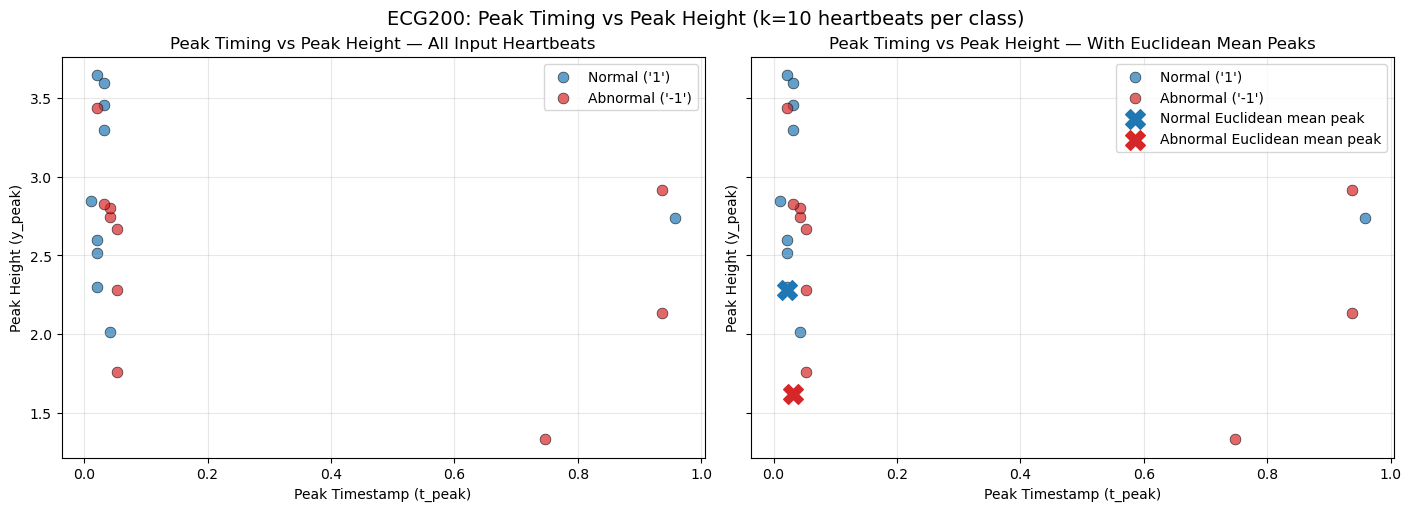

In [10]:
def peak_stats(waveforms, times):
    """Return (peak_times, peak_heights) for each waveform."""
    peak_indices = np.argmax(waveforms, axis=1)
    peak_times = times[peak_indices]
    peak_heights = waveforms[np.arange(len(waveforms)), peak_indices]
    return peak_times, peak_heights

normal_peak_times, normal_peak_heights = peak_stats(normal["waveforms"], normal["times"])
abnormal_peak_times, abnormal_peak_heights = peak_stats(abnormal["waveforms"], abnormal["times"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True,
                           constrained_layout=True)

axes[0].scatter(normal_peak_times, normal_peak_heights, c="tab:blue", s=60,
                alpha=0.7, edgecolors="black", linewidths=0.5, label="Normal ('1')")
axes[0].scatter(abnormal_peak_times, abnormal_peak_heights, c="tab:red", s=60,
                alpha=0.7, edgecolors="black", linewidths=0.5, label="Abnormal ('-1')")
axes[0].set_xlabel("Peak Timestamp (t_peak)")
axes[0].set_ylabel("Peak Height (y_peak)")
axes[0].set_title("Peak Timing vs Peak Height — All Input Heartbeats")
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

axes[1].scatter(normal_peak_times, normal_peak_heights, c="tab:blue", s=60,
                alpha=0.7, edgecolors="black", linewidths=0.5, label="Normal ('1')")
axes[1].scatter(abnormal_peak_times, abnormal_peak_heights, c="tab:red", s=60,
                alpha=0.7, edgecolors="black", linewidths=0.5, label="Abnormal ('-1')")
# Mark Euclidean mean peaks
ne_mean_idx = np.argmax(normal["waveforms"].mean(axis=0))
ae_mean_idx = np.argmax(abnormal["waveforms"].mean(axis=0))
axes[1].scatter(normal["times"][ne_mean_idx], normal["waveforms"].mean(axis=0)[ne_mean_idx],
                c="tab:blue", marker="X", s=200, label="Normal Euclidean mean peak", zorder=5)
axes[1].scatter(abnormal["times"][ae_mean_idx], abnormal["waveforms"].mean(axis=0)[ae_mean_idx],
                c="tab:red", marker="X", s=200, label="Abnormal Euclidean mean peak", zorder=5)
axes[1].set_xlabel("Peak Timestamp (t_peak)")
axes[1].set_ylabel("Peak Height (y_peak)")
axes[1].set_title("Peak Timing vs Peak Height — With Euclidean Mean Peaks")
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

fig.suptitle("ECG200: Peak Timing vs Peak Height (k=10 heartbeats per class)", fontsize=14)
plt.show()

## Visualization 3: Discrete Support Points & 2D Mass Density Heatmap

Top row: All input heartbeat points (gray) plus a single reference measure (colored) in the $(t, \tilde{y})$ plane.

Bottom row: 2D mass density heatmap of all heartbeat points, using a shared min-max y-scale across both classes so they are directly comparable.

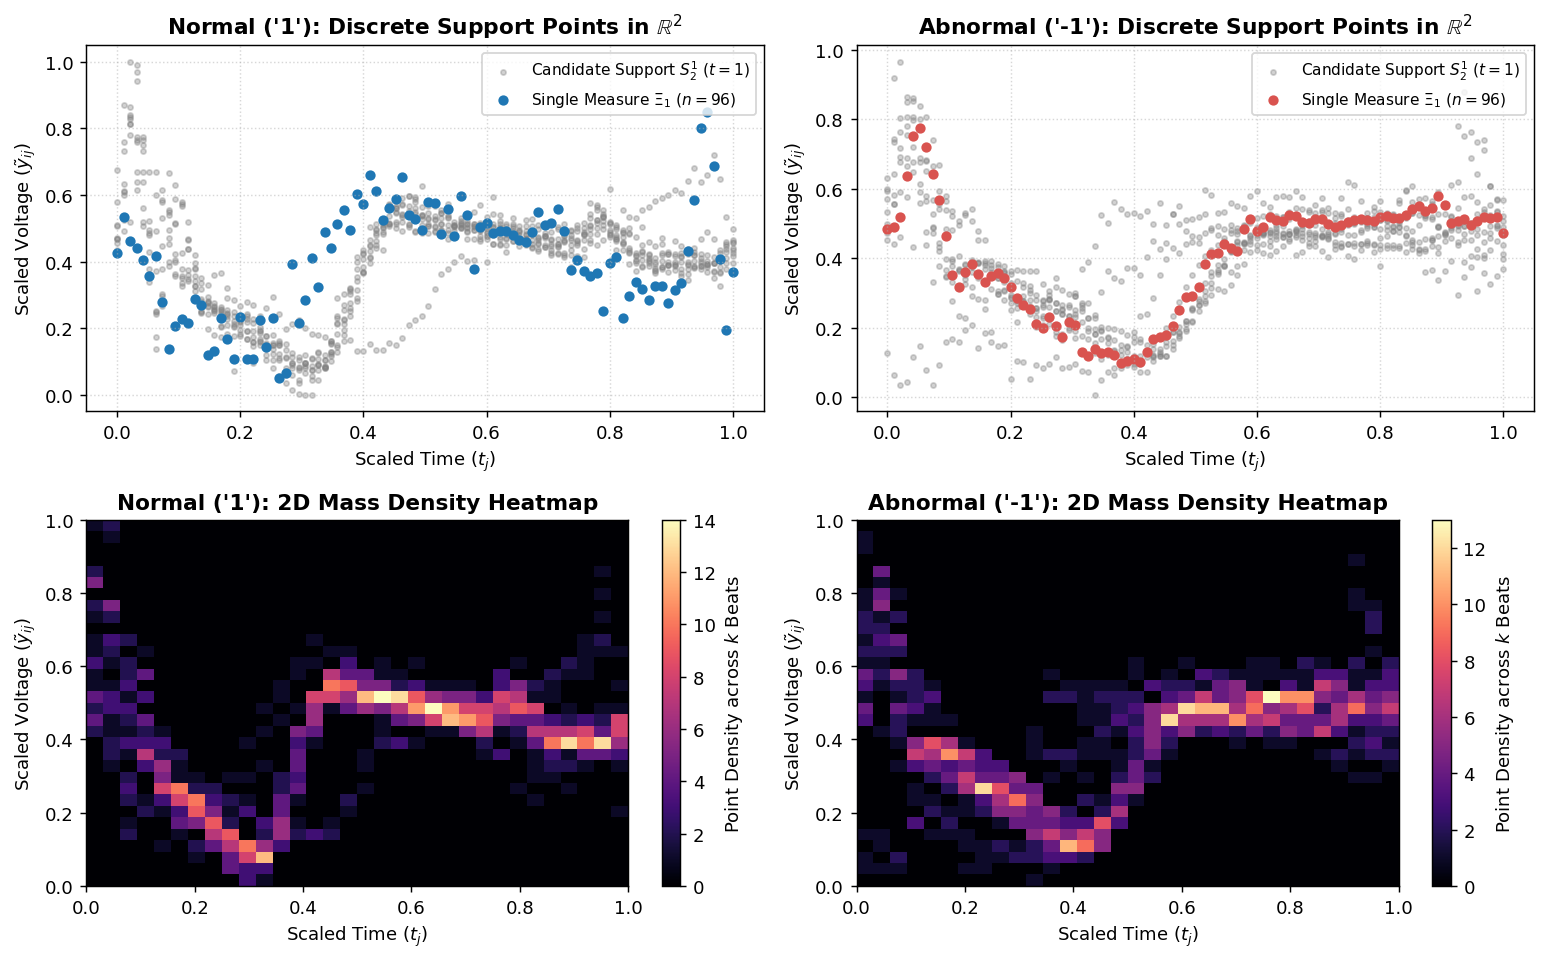

In [9]:
# Use a shared min-max scale across both classes so they are directly comparable
y_min = min(normal["waveforms"].min(), abnormal["waveforms"].min())
y_max = max(normal["waveforms"].max(), abnormal["waveforms"].max())

norm_scaled = (normal["waveforms"] - y_min) / (y_max - y_min)
abn_scaled = (abnormal["waveforms"] - y_min) / (y_max - y_min)

t = normal["times"]
k = normal["waveforms"].shape[0]

fig, ((ax_tl, ax_tr), (ax_bl, ax_br)) = plt.subplots(2, 2, figsize=(12, 7.5), dpi=130)

for ax_top, ax_bot, scaled_data, title, color in [
    (ax_tl, ax_bl, norm_scaled, "Normal ('1')", "#1f77b4"),
    (ax_tr, ax_br, abn_scaled, "Abnormal ('-1')", "#d9534f")
]:
    all_t = np.tile(t, k)
    all_y = scaled_data.flatten()

    # Top row: Discrete support points S_2^1 (t=1 candidate set)
    ax_top.scatter(all_t, all_y, s=8, color="gray", alpha=0.35,
                   label="Candidate Support $S_2^1$ ($t=1$)")
    ax_top.scatter(t, scaled_data[0], s=22, color=color,
                   label="Single Measure $\\Xi_1$ ($n=96$)")
    ax_top.set_title(f"{title}: Discrete Support Points in $\\mathbb{{R}}^2$", fontweight="bold")
    ax_top.set_xlabel("Scaled Time ($t_j$)")
    ax_top.set_ylabel("Scaled Voltage ($\\tilde{y}_{ij}$)")
    ax_top.legend(loc="upper right", fontsize=8.5)
    ax_top.grid(True, linestyle=":", alpha=0.5)

    # Bottom row: 2D Mass Density Heatmap (MNIST Image Analog)
    h = ax_bot.hist2d(all_t, all_y, bins=32, range=[[0, 1], [0, 1]], cmap="magma")
    plt.colorbar(h[3], ax=ax_bot, label="Point Density across $k$ Beats")
    ax_bot.set_title(f"{title}: 2D Mass Density Heatmap", fontweight="bold")
    ax_bot.set_xlabel("Scaled Time ($t_j$)")
    ax_bot.set_ylabel("Scaled Voltage ($\\tilde{y}_{ij}$)")

plt.tight_layout()
plt.show()

## Summary Statistics

Key metrics from the Algorithm 4 run.

In [8]:
summary_path = RESULTS_DIR / "ecg200_summary.json"
with open(summary_path) as f:
    summary = json.load(f)

for class_name in ("normal", "abnormal"):
    info = summary["classes"][class_name]
    print(f"\n{class_name.title()} class:")
    print(f"  Objective: {info['objective']:.8g}")
    print(f"  Runtime: {info['runtime_seconds']:.2f}s")
    print(f"  Active support size: {info['active_support_size']} / {info['support_size']}")
    print(f"  Mass sum: {info['mass_sum']:.8g}")


Normal class:
  Objective: 0.16840022
  Runtime: 188.57s
  Active support size: 306 / 960
  Mass sum: 1

Abnormal class:
  Objective: 0.21277722
  Runtime: 199.37s
  Active support size: 285 / 960
  Mass sum: 1
